# R-KalWeNN no House Prices

Notebook autossuficiente: todos os modelos, codificadores e médias estão
definidos aqui.

O foco é o R-KalWeNN. A Regression WiSARD entra só como definição e como número
de referência publicado, sem ser executada: o baseline vem da Tabela 2 do
Neurocomputing 416 (2020), que é revisado por pares.

| seção | conteúdo |
|---|---|
| 1 | configuração: todos os hiperparâmetros num lugar só |
| 2 | definições: thermometer, médias, endereçamento, Regression WiSARD |
| 3 | dados: pipeline do `houseprice.py`, alvo em `log1p` |
| 4 | R-KalWeNN: as duas variantes do filtro do peso |
| 5 | grid search conjunto |
| 6 | resultado contra a referência publicada |

**As duas variantes da seção 4 são independentes e estão em subseções
separadas**, para que a perdedora possa ser apagada sem tocar no resto.

---
# Seção 1 — Configuração

Tudo o que é hiperparâmetro está nesta célula.

In [117]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from itertools import product
from scipy.stats import skew, boxcox_normmax
from scipy.special import boxcox1p
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": .25,
    "axes.spines.top": False, "axes.spines.right": False,
})
COR_1, COR_B, COR_REF = "#2F6B6A", "#B4674D", "#8A8F98"

# ── dados ────────────────────────────────────────────────────────────────────
BASE_DADOS   = "https://raw.githubusercontent.com/ankita1112/House-Prices-Advanced-Regression/master/"
TEST_SIZE    = 0.33          # houseprice.py
RANDOM_STATE = 0             # houseprice.py

# ── codificação, fixada na configuração vencedora da varredura ───────────────
THERM        = 27            # bits de thermometer por atributo
ADDR         = 6             # bits por RAM node
SEED_MAPPING = 0

# ── referência publicada ─────────────────────────────────────────────────────
# Neurocomputing 416 (2020), Tabela 2: ReW no House Prices, média vencedora
# Median, MAE 0.278 com desvio 0. É o único baseline usado aqui.
REF_ARTIGO = 0.278

# ── estados iniciais, fixos nas duas variantes ───────────────────────────────
X0_C, X0_Y = 0.0, 0.0
SEEDS_GRID = (0, 1, 2)       # ordens de treino avaliadas por configuração

# ── FILTRO DA ESTIMATIVA y, comum às duas variantes ──────────────────────────
#   observação z = y_i, que vale cerca de 12 em log1p
#   r_y  variância do ruído de uma observação dessa ordem, logo r_y >= 1;
#        os níveis são 1, |y| e |y|^2
#   p0_y a crença inicial parte de x0_y = 0 e precisa cobrir a distância até 12;
#        covariância tem unidade de y^2, então a escala é 12^2 = 144
#   q_y  variação do estado entre observações, aplicada uma vez por VISITA
#        (passo_predicao="visita"). Com a semântica "exemplo" o passo roda a
#        cada exemplo do treino e o que age vira q_y/r_y * N/n, o que satura
#        as células raras: ver a seção 4.1.
GRID_R_Y  = [1.0, 12.0, 144.0]
GRID_P0_Y = [1.0, 12.0, 144.0]
GRID_Q_Y  = [1.5e-3, 1.5e-1, 1.5e1]

# ── FILTRO DO PESO c: observação z = 1 no acesso ────────────────────────────
#   c satura em 1 de forma assintótica. O que importa é o valor nas visitas que
#   a célula de fato recebe, e ele cobre [0,1] quando kappa é pequeno.
#   As faixas dão q/r de 1e-7 a 1e-3, ou seja, kappa de regime de 0.0003 a
#   0.031. Nenhuma satura na primeira visita.
GRID_R_C  = [1e-1, 1.0, 10.0]
GRID_P0_C = [1e-2, 1e-1, 1.0]
GRID_Q_C  = [1e-6, 1e-5, 1e-4] #[1e-6, 1e-5, 1e-4]

# ── quais médias entram no grid search ───────────────────────────────────────
# Só as adaptadas ao R-KalWeNN. As da ReW ficam definidas na seção 2.2 para a
# comparação entre as duas famílias, que fica para depois.
MEDIAS_NO_GRID = ["KSimpleMean", "KPowerMean(2)", "KHarmonicMean",
                  "KHarmonicPower(2)", "KExponentialMean", "KMedian"]

print(f"codificação: thermometer {THERM}, address {ADDR}, mapping seed {SEED_MAPPING}")
print(f"referência publicada (ReW, Median): MAE {REF_ARTIGO}")
print(f"grid do Kalman: 3^6 = {3**6} covariâncias x {len(MEDIAS_NO_GRID)} médias")

codificação: thermometer 27, address 6, mapping seed 0
referência publicada (ReW, Median): MAE 0.278
grid do Kalman: 3^6 = 729 covariâncias x 6 médias


---
# Seção 2 — Definições

## 2.1 Codificação: `DynamicThermometer`

Porte do `DynamicThermometer` do `wisardpkg`. Cada atributo vira $n$ bits. Os
limiares de um atributo com faixa $[\min, \max]$ são

$$
\tau_j = \min + j\,\frac{\max-\min}{n}, \qquad j = 0,\dots,n-1
$$

e o bit $j$ vale 1 quando $x > \tau_j$. O primeiro limiar é o próprio mínimo,
com comparação estrita, então o valor mínimo do treino gera o vetor todo zero.
Os limiares são acumulados e não calculados por multiplicação, para reproduzir
o mesmo arredondamento do `math::ranges` da referência.

In [118]:
class DynamicThermometer:
    """Termômetro por atributo, com faixa própria para cada um."""

    def __init__(self, sizes, minimos, maximos):
        self.sizes = list(sizes)
        self.limiares = []
        for n, mn, mx in zip(self.sizes, minimos, maximos):
            passo = (mx - mn) / n
            v, faixa = mn, []
            for _ in range(n):                # acumula, como o math::ranges
                faixa.append(v)
                v += passo
            self.limiares.append(np.asarray(faixa, dtype=float))
        self.size = int(np.sum(self.sizes))

    def transform(self, X):
        """(n_amostras, n_atributos) float -> (n_amostras, size) uint8."""
        X = np.atleast_2d(np.asarray(X, dtype=float))
        saida = np.empty((len(X), self.size), dtype=np.uint8)
        k = 0
        for i, faixa in enumerate(self.limiares):
            n = len(faixa)
            saida[:, k:k + n] = (X[:, [i]] > faixa[None, :]).astype(np.uint8)
            k += n
        return saida


print("DynamicThermometer definido")

DynamicThermometer definido


---
## 2.2 As médias

Duas famílias, porque as duas células guardam coisas diferentes.

**Família ReW.** A célula guarda contador $c_k$ e soma $S_k$. A estimativa da
RAM node é $\mu_k = S_k / c_k$, e o contador entra como **denominador**.

| média | fórmula |
|---|---|
| `SimpleMean` | $\sum_k S_k \big/ \sum_k c_k$ |
| `PowerMean(p)` | $\left(\frac{1}{m}\sum \mu_k^{\,p}\right)^{1/p}$ |
| `HarmonicMean` | $m \big/ \sum \mu_k^{-1}$ |
| `HarmonicPower(p)` | $\left(m \big/ \sum \mu_k^{-p}\right)^{1/p}$ |
| `ExponentialMean` | $\log\!\left(\frac{1 + \sum e^{\mu_k}}{m}\right)$ |
| `Median` | valor central dos $\mu_k$, pela fórmula da tese |

$m$ é o número de RAM nodes com $c_k \neq 0$. O `1 +` da `ExponentialMean` está
no código da referência (`double emean = 1`) e é mantido. A `Median` é o porte
do `Median::calculate` do `wisardpkg`, que é o que a tese executou.

**Família R-KalWeNN.** A célula guarda uma confiança $c_k \in [0,1)$ e um valor
esperado $y_k$. O $y_k$ já é a estimativa local, então não há divisão por
contador: o $c_k$ entra como **peso**, e a normalização é $\sum c_k$.

O prefixo `K` marca que são as fórmulas ponderadas que desenhamos para o
R-KalWeNN, e não as da Regression WiSARD.

| média | fórmula |
|---|---|
| `KSimpleMean` | $\dfrac{\sum c_k y_k}{\sum c_k}$ |
| `KPowerMean(p)` | $\left(\dfrac{\sum c_k y_k^{\,p}}{\sum c_k}\right)^{1/p}$ |
| `KHarmonicMean` | $\dfrac{\sum c_k}{\sum c_k / y_k}$ |
| `KHarmonicPower(p)` | $\left(\dfrac{\sum c_k}{\sum c_k / y_k^{\,p}}\right)^{1/p}$ |
| `KExponentialMean` | $\log\!\left(\dfrac{\sum c_k e^{y_k}}{\sum c_k}\right)$ |
| `KMedian` | $y$ onde o $c$ acumulado cruza $\tfrac{1}{2}\sum c_k$ |

Onde a ReW divide por $c_k$, aqui multiplica. O $\sum c_k$ no denominador é o
que impede o resultado de encolher: sem ele, multiplicar por $c_k < 1$ puxaria
a predição para baixo do valor esperado.

Duas diferenças deliberadas em relação à família ReW. Só entram células com
evidência, em vez de passar $[0,0]$ e cada média filtrar. E o `1 +` da
exponencial foi retirado, porque não tem lugar numa forma normalizada por
$\sum c_k$.

`GeometricMean` e `LogisticMean` ficaram de fora das duas famílias. A geométrica
acumula um produto de $\mu_k \approx 12$ sobre as RAM nodes e estoura o `double`
com mais de 285 delas; a logística devolve sempre um valor em $(0,1)$, e o alvo
vale 12.

Harmônica e harmônica-potência exigem $y_k > 0$. Com o alvo em `log1p` isso
vale sempre, e a condição está escrita no código.

In [119]:
# ─────────────────────────── família ReW ─────────────────────────────────────
class Mean:
    """`output_rams` é uma lista de [contador, soma_y], incluindo as RAM nodes
    não visitadas como [0, 0], como no predict da referência."""
    nome = "Mean"
    def calculate(self, output_rams):
        raise NotImplementedError
    def __repr__(self):
        return f"ReW.{self.nome}"


class SimpleMean(Mean):
    nome = "SimpleMean"
    def calculate(self, output_rams):
        sc = sum(c for c, _ in output_rams)
        sy = sum(y for _, y in output_rams)
        return sy / sc if sc > 0 else 0.0


class PowerMean(Mean):
    def __init__(self, power=2):
        self.power = power; self.nome = f"PowerMean({power})"
    def calculate(self, output_rams):
        s, m = 0.0, 0
        for c, y in output_rams:
            if c != 0:
                s += (y / c) ** self.power; m += 1
        return (s / m) ** (1.0 / self.power) if m > 0 else 0.0


class HarmonicMean(Mean):
    nome = "HarmonicMean"
    def calculate(self, output_rams):
        s, m = 0.0, 0
        for c, y in output_rams:
            if c != 0:
                mu = y / c
                if mu != 0:
                    s += 1.0 / mu; m += 1
        return m / s if m > 0 else 0.0


class HarmonicPowerMean(Mean):
    def __init__(self, power=2):
        self.power = power; self.nome = f"HarmonicPower({power})"
    def calculate(self, output_rams):
        s, m = 0.0, 0
        for c, y in output_rams:
            if c != 0:
                mu = y / c
                if mu != 0:
                    s += 1.0 / (mu ** self.power); m += 1
        return (m / s) ** (1.0 / self.power) if m > 0 else 0.0


class ExponentialMean(Mean):
    nome = "ExponentialMean"
    def calculate(self, output_rams):
        e, m = 1.0, 0                          # começa em 1, como na referência
        for c, y in output_rams:
            if c != 0:
                e += np.exp(y / c); m += 1
        return float(np.log(e / m)) if m > 0 else 0.0


class Median(Mean):
    """Porte do Median::calculate do wisardpkg, que é o que a tese executou.

    Divide sem checar contador zero, ao contrário das outras médias, e usa
    índice deslocado em um. Onde a referência leria fora do vetor, aqui devolve
    NaN em vez de ler lixo de memória, e os NaN vão para o fim da ordenação.
    """
    nome = "Median"
    def calculate(self, output_rams):
        mus = [np.divide(float(y), float(c)) if c != 0 else float("nan")
               for c, y in output_rams]
        mus = sorted(mus, key=lambda v: (np.isnan(v), v))
        n = len(mus)
        if n % 2 == 0:
            i = n // 2
            return (mus[i] + mus[i + 1]) / 2.0 if i + 1 < n else float("nan")
        i = (n - 1) // 2 + 1
        return mus[i] if i < n else float("nan")


def medias_rew():
    return {"SimpleMean": SimpleMean(), "PowerMean(2)": PowerMean(2),
            "HarmonicMean": HarmonicMean(), "HarmonicPower(2)": HarmonicPowerMean(2),
            "ExponentialMean": ExponentialMean(), "Median": Median()}


print("médias da família ReW:", ", ".join(medias_rew()))

médias da família ReW: SimpleMean, PowerMean(2), HarmonicMean, HarmonicPower(2), ExponentialMean, Median


In [120]:
# ────────────────────── família R-KalWeNN (ponderadas) ───────────────────────
class MediaPonderada:
    """`pares` é uma lista de (c_k, y_k) das células COM evidência.

    c_k é confiança em [0,1), y_k é o valor esperado local.
    Todas normalizam por sum(c), o que mantém o resultado na escala do alvo.
    """
    nome = "MediaPonderada"
    def calculate(self, pares):
        raise NotImplementedError
    def __repr__(self):
        return self.nome


class PondSimpleMean(MediaPonderada):
    nome = "KSimpleMean"
    def calculate(self, pares):
        sc = sum(c for c, _ in pares)
        return sum(c * y for c, y in pares) / sc if sc > 0 else np.nan


class PondPowerMean(MediaPonderada):
    def __init__(self, power=2):
        self.power = power; self.nome = f"KPowerMean({power})"
    def calculate(self, pares):
        sc = sum(c for c, _ in pares)
        if sc <= 0:
            return np.nan
        return (sum(c * y ** self.power for c, y in pares) / sc) ** (1.0 / self.power)


class PondHarmonicMean(MediaPonderada):
    nome = "KHarmonicMean"
    def calculate(self, pares):
        sc = s = 0.0
        for c, y in pares:
            if y > 0:
                sc += c; s += c / y
        return sc / s if s > 0 else np.nan


class PondHarmonicPowerMean(MediaPonderada):
    def __init__(self, power=2):
        self.power = power; self.nome = f"KHarmonicPower({power})"
    def calculate(self, pares):
        sc = s = 0.0
        for c, y in pares:
            if y > 0:
                sc += c; s += c / y ** self.power
        return (sc / s) ** (1.0 / self.power) if s > 0 else np.nan


class PondExponentialMean(MediaPonderada):
    nome = "KExponentialMean"
    def calculate(self, pares):
        sc = sum(c for c, _ in pares)
        if sc <= 0:
            return np.nan
        return float(np.log(sum(c * np.exp(y) for c, y in pares) / sc))


class PondMedian(MediaPonderada):
    """Mediana ponderada: y onde o c acumulado cruza metade de sum(c)."""
    nome = "KMedian"
    def calculate(self, pares):
        pares = sorted(pares, key=lambda t: t[1])
        total = sum(c for c, _ in pares)
        if total <= 0:
            return np.nan
        meio, acum = total / 2.0, 0.0
        for c, y in pares:
            acum += c
            if acum >= meio:
                return y
        return pares[-1][1]


def medias_kal():
    """Prefixo K: fórmulas ponderadas, desenhadas para o R-KalWeNN.

    Não são as da Regression WiSARD, que estão em `medias_rew()`."""
    return {"KSimpleMean": PondSimpleMean(), "KPowerMean(2)": PondPowerMean(2),
            "KHarmonicMean": PondHarmonicMean(),
            "KHarmonicPower(2)": PondHarmonicPowerMean(2),
            "KExponentialMean": PondExponentialMean(), "KMedian": PondMedian()}


print("médias da família R-KalWeNN:", ", ".join(medias_kal()))

médias da família R-KalWeNN: KSimpleMean, KPowerMean(2), KHarmonicMean, KHarmonicPower(2), KExponentialMean, KMedian


---
## 2.3 Endereçamento

O `mapping` é uma permutação dos bits da retina. A RAM node $i$ lê as posições
`mapping[i*addr : (i+1)*addr]`, e o endereço é montado com o bit menos
significativo primeiro, como no `getIndex` da referência:

$$
a_i \;=\; \sum_{j=0}^{\text{addr}-1} b_{\,\text{mapping}[i\cdot\text{addr}+j]} \cdot 2^{\,j}
$$

As duas variantes do R-KalWeNN e a Regression WiSARD compartilham esta classe.

In [121]:
class Retina:
    """Converte entrada binarizada em endereços, um por RAM node."""

    def __init__(self, address_size, mapping):
        self.address_size = int(address_size)
        self.mapping = np.asarray(mapping, dtype=int).reshape(-1, self.address_size)
        self.n_rams = self.mapping.shape[0]
        self.n_addr = 1 << self.address_size
        self._pesos = 1 << np.arange(self.address_size)     # LSB primeiro

    def enderecos(self, Xb):
        """(n, retina) uint8 -> (n, n_rams) int."""
        Xb = np.asarray(Xb, dtype=np.uint8)
        return (Xb[:, self.mapping] * self._pesos).sum(axis=2).astype(np.int64)


def sorteia_mapping(retina_bits, address_size, seed=0):
    """Permutação dos bits da retina, truncada a um múltiplo de address_size."""
    n_rams = retina_bits // address_size
    rng = np.random.default_rng(seed)
    return rng.permutation(retina_bits)[: n_rams * address_size].tolist()


print("Retina definida")

Retina definida


---
## 2.4 Regression WiSARD

Definida para referência e para a comparação entre as duas famílias de média,
que fica para depois. **Não é executada neste notebook**: o baseline do House
Prices vem do número publicado, não de uma execução nossa.

Cada célula guarda dois números, o contador e a soma dos $y$:

$$
c_k \leftarrow c_k + 1, \qquad S_k \leftarrow S_k + y_i
$$

A predição entrega a lista de pares $[c_k, S_k]$ de todas as RAM nodes para a
média escolhida, incluindo as não visitadas como $[0,0]$.

In [122]:
class RegressionWiSARD:
    """Regression WiSARD. Recebe entrada já binarizada."""

    def __init__(self, address_size, mean, mapping):
        self.retina = Retina(address_size, mapping)
        self.mean = mean

    @property
    def n_rams_(self):
        return self.retina.n_rams

    def fit(self, Xb, y):
        y = np.asarray(y, dtype=float)
        addr = self.retina.enderecos(Xb)
        self._mem = [dict() for _ in range(self.n_rams_)]
        for i in range(len(y)):
            for r_ in range(self.n_rams_):
                cel = self._mem[r_].get(addr[i, r_])
                if cel is None:
                    self._mem[r_][addr[i, r_]] = [1.0, y[i]]
                else:
                    cel[0] += 1.0; cel[1] += y[i]
        return self

    def predict(self, Xb):
        addr = self.retina.enderecos(Xb)
        vazia = [0.0, 0.0]
        return np.array([
            self.mean.calculate([self._mem[r_].get(addr[i, r_], vazia)
                                 for r_ in range(self.n_rams_)])
            for i in range(len(addr))])

    def memoria_bytes(self):
        return sum(len(m) for m in self._mem) * 24    # chave + 2 floats


print("RegressionWiSARD definida (não é executada neste notebook)")

RegressionWiSARD definida (não é executada neste notebook)


---
# Seção 3 — Dados

Pipeline do `referencia_lusquino/regression/houseprice/houseprice.py`, linha por
linha. Alvo em `log1p`, que é o que está na linha 82 do script publicado.

Os dois arquivos do Kaggle são concatenados em `all_data` **antes** da
imputação, como no original. Isso significa que as estatísticas de imputação, as
colunas do one-hot e a correção de assimetria enxergam o `test.csv`. É
vazamento, e está assim porque o objetivo é usar exatamente o mesmo conjunto que
produziu o número publicado. O `test.csv` nunca entra na avaliação.

## 3.1 Carregamento e transformação do alvo

In [123]:
train = pd.read_csv(BASE_DADOS + "train.csv")
test  = pd.read_csv(BASE_DADOS + "test.csv")

train = train[train.GrLivArea < 4500]                  # linha 73 do original
train.reset_index(drop=True, inplace=True)
train["SalePrice"] = np.log1p(train["SalePrice"])      # linha 82: alvo em log1p

train.drop(columns=["Id"], axis=1, inplace=True)
test.drop(columns=["Id"], axis=1, inplace=True)
y = train["SalePrice"].reset_index(drop=True)

all_data = pd.concat((train, test)).reset_index(drop=True)   # linha 106
all_data.drop(["SalePrice"], axis=1, inplace=True)

print(f"train.csv: {train.shape}   test.csv: {test.shape}")
print(f"alvo em log1p: {y.min():.4f} a {y.max():.4f}   média {y.mean():.4f}   desvio {y.std():.4f}")
print(f"  em dólares: ${np.expm1(y.min()):,.0f} a ${np.expm1(y.max()):,.0f}")
print(f"all_data: {all_data.shape}")

train.csv: (1458, 80)   test.csv: (1459, 79)
alvo em log1p: 10.4603 a 13.5345   média 12.0240   desvio 0.3997
  em dólares: $34,900 a $755,000
all_data: (2917, 79)


## 3.2 Imputação

| grupo | política |
|---|---|
| categóricas onde ausência tem significado | string `'None'` |
| numéricas de área e porão | `0` |
| `LotFrontage` | média do `Neighborhood` |

In [124]:
for c in ["Alley", "PoolQC", "MiscFeature", "Fence", "FireplaceQu", "GarageType",
          "GarageFinish", "GarageQual", "GarageCond", "BsmtQual", "BsmtCond",
          "BsmtExposure", "BsmtFinType1", "BsmtFinType2", "MasVnrType"]:
    all_data[c] = all_data[c].fillna("None")

for c in ["BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath",
          "BsmtHalfBath", "GarageYrBlt", "GarageArea", "GarageCars", "MasVnrArea"]:
    all_data[c] = all_data[c].fillna(0)

all_data["LotFrontage"] = all_data.groupby("Neighborhood")["LotFrontage"].transform(
    lambda x: x.fillna(x.mean()))

all_data["MSSubClass"] = all_data["MSSubClass"].astype(str)   # códigos, não quantidades
all_data["MSZoning"] = all_data.groupby("MSSubClass")["MSZoning"].transform(
    lambda x: x.fillna(x.mode()[0]))
all_data["YrSold"] = all_data["YrSold"].astype(str)
all_data["MoSold"] = all_data["MoSold"].astype(str)

all_data["Functional"]  = all_data["Functional"].fillna("Typ")
all_data["Utilities"]   = all_data["Utilities"].fillna("AllPub")
all_data["Exterior1st"] = all_data["Exterior1st"].fillna(all_data["Exterior1st"].mode()[0])
all_data["Exterior2nd"] = all_data["Exterior2nd"].fillna(all_data["Exterior2nd"].mode()[0])
all_data["KitchenQual"] = all_data["KitchenQual"].fillna("TA")
all_data["SaleType"]    = all_data["SaleType"].fillna(all_data["SaleType"].mode()[0])
all_data["Electrical"]  = all_data["Electrical"].fillna("SBrkr")

print(f"colunas com NaN restante: {(all_data.isna().sum() > 0).sum()}")

colunas com NaN restante: 0


## 3.3 Correção de assimetria, atributos derivados e one-hot

Colunas numéricas com assimetria acima de 0,5 passam por `boxcox1p`. Em versões
novas do scipy o `boxcox_normmax` com o método padrão `pearsonr` levanta
`BracketError` em algumas colunas; elas ficam sem transformar, o que é mais
seguro que o método `mle`, que para `YearRemodAdd` devolve lambda 40,6.

In [125]:
def fixing_skewness(df):
    puladas = []
    numeric = df.dtypes[df.dtypes != "object"].index
    skewed = df[numeric].apply(lambda x: skew(x)).sort_values(ascending=False)
    alvo = skewed[abs(skewed) > 0.5].index
    for feat in alvo:
        try:
            df[feat] = boxcox1p(df[feat], boxcox_normmax(df[feat] + 1))
        except Exception:
            puladas.append(feat)
    return len(alvo), puladas


n_alvo, puladas = fixing_skewness(all_data)
print(f"boxcox aplicado em {n_alvo - len(puladas)} de {n_alvo} colunas assimétricas")
if puladas:
    print(f"  sem transformar (BracketError do scipy): {puladas}")

all_data = all_data.drop(["Utilities", "Street", "PoolQC"], axis=1)

all_data["TotalSF"]       = all_data["TotalBsmtSF"] + all_data["1stFlrSF"] + all_data["2ndFlrSF"]
all_data["YrBltAndRemod"] = all_data["YearBuilt"] + all_data["YearRemodAdd"]
all_data["Total_sqr_footage"] = (all_data["BsmtFinSF1"] + all_data["BsmtFinSF2"] +
                                 all_data["1stFlrSF"] + all_data["2ndFlrSF"])
all_data["Total_Bathrooms"]   = (all_data["FullBath"] + 0.5 * all_data["HalfBath"] +
                                 all_data["BsmtFullBath"] + 0.5 * all_data["BsmtHalfBath"])
all_data["Total_porch_sf"]    = (all_data["OpenPorchSF"] + all_data["3SsnPorch"] +
                                 all_data["EnclosedPorch"] + all_data["ScreenPorch"] +
                                 all_data["WoodDeckSF"])

all_data["haspool"]      = (all_data["PoolArea"]    > 0).astype(int)
all_data["has2ndfloor"]  = (all_data["2ndFlrSF"]    > 0).astype(int)
all_data["hasgarage"]    = (all_data["GarageArea"]  > 0).astype(int)
all_data["hasbsmt"]      = (all_data["TotalBsmtSF"] > 0).astype(int)
all_data["hasfireplace"] = (all_data["Fireplaces"]  > 0).astype(int)

final_features = pd.get_dummies(all_data).reset_index(drop=True)
print(f"depois do one-hot: {final_features.shape}")

/Users/helenaburock/Git/estudos_ml/.venv/lib/python3.9/site-packages/scipy/stats/_morestats.py:1298: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, prob = _stats_py.pearsonr(xvals, yvals)
/Users/helenaburock/Git/estudos_ml/.venv/lib/python3.9/site-packages/scipy/stats/_morestats.py:1298: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, prob = _stats_py.pearsonr(xvals, yvals)


boxcox aplicado em 25 de 27 colunas assimétricas
  sem transformar (BracketError do scipy): ['LotArea', '1stFlrSF']
depois do one-hot: (2917, 333)


## 3.4 Outliers, `overfit_reducer` e split

`overfit_reducer`: descarta colunas em que um único valor aparece em mais de
99,94% das linhas.

In [126]:
X = final_features.iloc[:len(y), :]

outliers = [30, 88, 462, 631, 1322]
X  = X.drop(X.index[outliers])
y_ = y.drop(y.index[outliers])

def overfit_reducer(df):
    return [c for c in df.columns
            if df[c].value_counts().iloc[0] / len(df) * 100 > 99.94]

descartadas = overfit_reducer(X)
X = X.drop(descartadas, axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_, test_size=TEST_SIZE, random_state=RANDOM_STATE)
X_train, X_test = X_train.values.astype(float), X_test.values.astype(float)
y_train, y_test = y_train.values, y_test.values
N_TREINO, N_ATRIB = len(X_train), X_train.shape[1]

print(f"overfit_reducer descartou {len(descartadas)} colunas -> {X.shape}")
print(f"treino {N_TREINO}   teste {len(X_test)}   atributos {N_ATRIB}")
print(f"a tese reporta:  treino 973   teste 480")
print(f"alvo (log1p): treino {y_train.min():.3f} a {y_train.max():.3f}")

overfit_reducer descartou 1 colunas -> (1453, 332)
treino 973   teste 480   atributos 332
a tese reporta:  treino 973   teste 480
alvo (log1p): treino 10.460 a 13.534


## 3.5 Distribuição do alvo e referências de erro

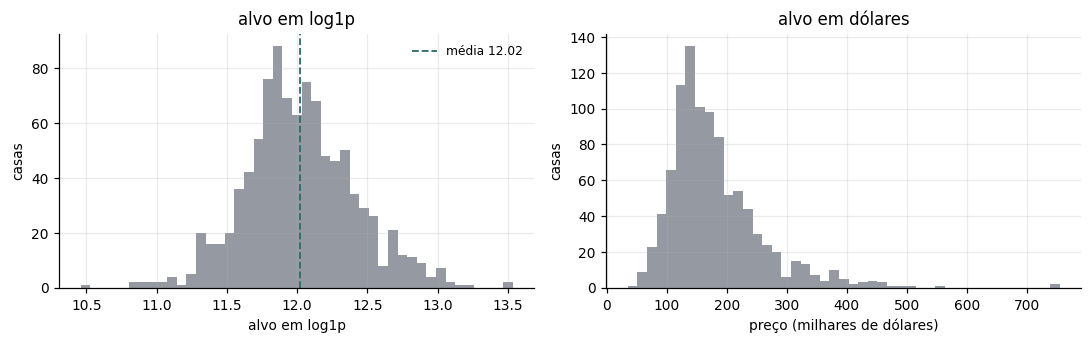

REFERÊNCIAS (escala log1p)

  chutar a média do treino   : MAE 0.3151
  chutar a mediana do treino : MAE 0.3156

  ReW publicada (Neurocomputing 416, Tabela 2): MAE 0.278

  variância do alvo no treino: 0.1537   desvio 0.3920
  0.278 em log1p equivale a 32.0% de erro relativo


In [127]:
mae_media   = mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))
mae_mediana = mean_absolute_error(y_test, np.full(len(y_test), np.median(y_train)))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(y_train, bins=45, color=COR_REF, alpha=.9)
ax[0].axvline(y_train.mean(), color=COR_1, ls="--", lw=1.2, label=f"média {y_train.mean():.2f}")
ax[0].set(xlabel="alvo em log1p", ylabel="casas", title="alvo em log1p")
ax[0].legend(frameon=False, fontsize=8)
ax[1].hist(np.expm1(y_train) / 1e3, bins=45, color=COR_REF, alpha=.9)
ax[1].set(xlabel="preço (milhares de dólares)", ylabel="casas", title="alvo em dólares")
plt.tight_layout(); plt.show()

print("REFERÊNCIAS (escala log1p)\n")
print(f"  chutar a média do treino   : MAE {mae_media:.4f}")
print(f"  chutar a mediana do treino : MAE {mae_mediana:.4f}")
print(f"\n  ReW publicada (Neurocomputing 416, Tabela 2): MAE {REF_ARTIGO:.3f}")
print(f"\n  variância do alvo no treino: {y_train.var():.4f}   desvio {y_train.std():.4f}")
print(f"  {REF_ARTIGO:.3f} em log1p equivale a {np.expm1(REF_ARTIGO):.1%} de erro relativo")

## 3.6 Binarização e mapping

Uma binarização e um `mapping` só, compartilhados por tudo que roda daqui para
baixo, para que a comparação entre as duas variantes seja controlada.

In [128]:
mins = X_train.min(axis=0).tolist()
maxs = X_train.max(axis=0).tolist()
DT = DynamicThermometer([THERM] * N_ATRIB, mins, maxs)

Xb_train = DT.transform(X_train)
Xb_test  = DT.transform(X_test)

RETINA  = Xb_train.shape[1]
MAPPING = sorteia_mapping(RETINA, ADDR, seed=SEED_MAPPING)
RET_OBJ = Retina(ADDR, MAPPING)
N_RAMS  = RET_OBJ.n_rams
N_ADDR  = RET_OBJ.n_addr

ADDR_TR = RET_OBJ.enderecos(Xb_train)
ADDR_TE = RET_OBJ.enderecos(Xb_test)

visitas = np.zeros((N_RAMS, N_ADDR), dtype=int)
for i in range(N_TREINO):
    visitas[np.arange(N_RAMS), ADDR_TR[i]] += 1
ocupadas = visitas[visitas > 0]

print(f"retina   : {RETINA} bits  ({N_ATRIB} atributos x {THERM})")
print(f"address  : {ADDR} bits  ->  {N_RAMS} RAM nodes x {N_ADDR} endereços")
print(f"mapping  : {len(MAPPING)} bits, seed {SEED_MAPPING}")
print(f"\ncélulas ocupadas: {len(ocupadas):,} de {N_RAMS*N_ADDR:,}")
print(f"visitas por célula ocupada: mín {ocupadas.min()}, mediana "
      f"{int(np.median(ocupadas))}, máx {ocupadas.max()}")

retina   : 8964 bits  (332 atributos x 27)
address  : 6 bits  ->  1494 RAM nodes x 64 endereços
mapping  : 8964 bits, seed 0

células ocupadas: 23,172 de 95,616
visitas por célula ocupada: mín 1, mediana 6, máx 952


---
# Seção 4 — R-KalWeNN

A Regression WiSARD guarda contador e soma. O R-KalWeNN troca os dois campos da
célula por estados de um filtro de Kalman escalar:

| campo | o que é | converge para |
|---|---|---|
| $c_k$ | confiança do endereço, em $[0,1)$ | 1, de forma assintótica |
| $y_k$ | valor esperado de $y$ naquele endereço | a média local de $y$ |
| $p_{c,k}$, $p_{y,k}$ | covariância de cada filtro | regime dado por $q$ e $r$ |

Recursão, a cada observação:

$$
\bar{p} = p + q \qquad \kappa = \frac{\bar{p}}{\bar{p} + r} \qquad
x \leftarrow x + \kappa\,(z - x) \qquad p \leftarrow (1-\kappa)\,\bar{p}
$$

Predição, com a média escolhida sobre os pares $(c_k, y_k)$ das células que o
exemplo endereça e que têm evidência:

$$
\hat{y} \;=\; \text{média}_{\,k}\big(c_k,\, y_k\big)
$$

## 4.1 Os dois filtros

**Estados iniciais.** $x_{0,c} = x_{0,y} = 0$, fixos. As covariâncias iniciais
são hiperparâmetros e nunca são zero: covariância nula não descreve uma
gaussiana, descreve um ponto exato no espaço de estados.

**Filtro do peso $c$.** Observação $z = 1$ quando o endereço é acessado; célula
não acessada não é tocada. É o `KalmanWiSARD` de classificação sem alteração.

**Filtro da estimativa $y$.** A correção roda só no acesso, porque só aí existe
um $y$ para observar. O passo de predição tem duas semânticas, escolhidas pelo
parâmetro `passo_predicao`:

$$
\text{"visita"}: \quad p_y \leftarrow p_y + q_y \ \text{ a cada acesso}
\qquad\qquad
\text{"exemplo"}: \quad p_y \leftarrow p_y + q_y \ \text{ a cada exemplo}
$$

$$
\kappa_y = \frac{p_y}{p_y + r_y}, \qquad y \leftarrow y + \kappa_y (y_i - y)
\qquad \text{(só no acesso, nas duas)}
$$

A diferença é grande. Em `"exemplo"`, uma célula de $n$ visitas passa cerca de
$N/n$ exemplos sem correção, então o que age não é $q_y/r_y$ e sim
$q_y/r_y \cdot N/n$. Medido: com $q_y/r_y = 10^{-2}$, uma célula de 6 visitas
chega a ganho 0,619 enquanto uma de 543 fica em 0,018. Nenhum valor deixa as
duas pontas num regime útil ao mesmo tempo, e o grid conjunto acabou escolhendo
o extremo $q_y/r_y = 15$, em que o ganho é praticamente 1 em toda célula e o $y$
vira o último valor observado.

Em `"visita"`, a mesma faixa produz ganho entre 0,01 e 0,29 em qualquer contagem
de visitas, o que devolve ao filtro uma região de operação. É o padrão.

---
## 4.2 O que a confiança mede, e o que ela não mede

$c$ vai assintoticamente para 1, mas nenhuma célula chega lá: o que importa é o
valor depois das visitas que ela de fato recebe. Como o passo não depende do
valor observado, $c$ é função determinística do número de visitas,

$$
c(n) \;=\; 1 - \prod_{j=1}^{n}\big(1 - \kappa_{c,j}\big)
$$

e com $\kappa$ pequeno essa curva cobre $[0,1]$ ao longo da faixa real de
visitas. Com $q_c/r_c = 10^{-4}$, por exemplo, dá 0,010 para uma visita e 0,996
para 543, uma razão de 100x contra 543x do contador puro da ReW.

**O que ela é.** Um contador que satura, com retorno decrescente por visita, e a
taxa de saturação é o hiperparâmetro.

**O que ela não é.** Uma medida de acerto. Duas células com o mesmo número de
visitas têm exatamente o mesmo $c$, mesmo que os $y$ de uma concordem e os da
outra não. Isso vale para $p$ também, porque a recursão da covariância não
contém $z$.

**Implementação.** Como $c$ só depende do contador e $p_y$ só depende do número
de passos desde a última correção, nada precisa tocar as células não acessadas.
A memória fica esparsa, com apenas as células visitadas, e não há teto no
`address_size`, o que é o que permite a varredura da seção 8.

In [129]:
class IndiceRK:
    """(ram, address) -> slot compacto, construído uma vez por (retina, treino).

    Só existem células que algum exemplo de treino visitou, o que vale para
    qualquer `address_size`: uma tabela densa de 2^address entradas por RAM node
    seria impossível já com 20 bits.
    """

    def __init__(self, retina, addr_fit):
        self.retina = retina
        self.slots_fit = np.empty_like(addr_fit)
        self._tab, off = [], 0
        for r_ in range(retina.n_rams):
            uniq, inv = np.unique(addr_fit[:, r_], return_inverse=True)
            self.slots_fit[:, r_] = inv + off
            self._tab.append((uniq, off))
            off += len(uniq)
        self.n_celulas = off

    def slots(self, addr):
        """(n, n_rams), com -1 onde o endereço não apareceu no treino."""
        out = np.full(addr.shape, -1, dtype=np.int64)
        for r_ in range(self.retina.n_rams):
            uniq, off = self._tab[r_]
            pos = np.clip(np.searchsorted(uniq, addr[:, r_]), 0, len(uniq) - 1)
            ok = uniq[pos] == addr[:, r_]
            out[ok, r_] = off + pos[ok]
        return out


print("IndiceRK definido")

IndiceRK definido


In [130]:
class RKalWeNN:
    """R-KalWeNN: Kalman nos dois campos da célula. Memória esparsa.

    FILTRO DO PESO c   observação z = 1 no acesso; célula não acessada não é
                       tocada. Como a recursão da covariância não contém z, o
                       estado c é função determinística do NÚMERO de visitas:

                           c(n) = 1 - prod_{j=1..n} (1 - kappa_j)

                       então ele é montado no fim, a partir dos contadores, sem
                       precisar de laço por exemplo.

    FILTRO DA ESTIMATIVA y   correção só no acesso. O passo de predição tem duas
                       semânticas, escolhidas por `passo_predicao`:

                       "visita"  (padrão) p_y cresce q_y uma vez por acesso.
                                 q_y/r_y age direto e a mesma faixa produz
                                 ganho útil em célula rara e em célula densa.

                       "exemplo" p_y cresce q_y a cada exemplo do treino, mesmo
                                 sem acesso. Entre dois acessos de uma célula de
                                 n visitas passam ~N/n exemplos, então o que age
                                 é q_y/r_y * N/n: célula de 6 visitas satura em
                                 q_y/r_y = 1e-2 enquanto célula de 543 ainda tem
                                 ganho 0,018. Não existe valor que deixe as duas
                                 pontas num regime útil ao mesmo tempo.

    As duas coisas juntas deixam a memória esparsa: só existem células que algum
    exemplo de treino visitou. Não há teto no `address_size`.
    """

    def __init__(self, address_size, mapping, media=None,
                 q_c=1e-5, r_c=1.0, p0_c=1e-1,
                 q_y=1.5e-3, r_y=1.0, p0_y=144.0,
                 x0_c=0.0, x0_y=0.0, seed=0, indice=None,
                 passo_predicao="visita"):
        self.retina = Retina(address_size, mapping)
        self.media = media if media is not None else PondSimpleMean()
        self.q_c, self.r_c, self.p0_c = q_c, r_c, p0_c
        self.q_y, self.r_y, self.p0_y = q_y, r_y, p0_y
        self.x0_c, self.x0_y, self.seed = x0_c, x0_y, seed
        self.indice = indice
        if passo_predicao not in ("visita", "exemplo"):
            raise ValueError("passo_predicao deve ser 'visita' ou 'exemplo'")
        self.passo_predicao = passo_predicao

    @property
    def n_rams_(self):
        return self.retina.n_rams

    def tabela_c(self, nmax):
        """c(n) para n = 0..nmax. Não depende dos dados, só das covariâncias."""
        tab = np.zeros(nmax + 1)
        x, p = self.x0_c, self.p0_c
        for n in range(1, nmax + 1):
            pb = p + self.q_c
            k = pb / (pb + self.r_c)
            x += k * (1.0 - x)
            p = (1.0 - k) * pb
            tab[n] = x
        return tab

    def fit(self, Xb=None, y=None, addr=None):
        y = np.asarray(y, dtype=float)
        if self.indice is None:
            self.indice = IndiceRK(self.retina,
                                   self.retina.enderecos(Xb) if addr is None else addr)
        idx = self.indice
        ordem = np.random.default_rng(self.seed).permutation(len(y))

        Y    = np.full(idx.n_celulas, self.x0_y)
        PY   = np.full(idx.n_celulas, self.p0_y)
        ult  = np.zeros(idx.n_celulas)                 # passos já aplicados
        cont = np.zeros(idx.n_celulas, dtype=np.int64)

        por_visita = self.passo_predicao == "visita"
        for passo, i in enumerate(ordem, start=1):
            s = idx.slots_fit[i]
            # predição: uma vez por visita, ou acumulada desde a última correção
            pp = PY[s] + (self.q_y if por_visita else self.q_y * (passo - ult[s]))
            ky = pp / (pp + self.r_y)                  # correção, só no acesso
            Y[s] += ky * (y[i] - Y[s])
            PY[s] = (1.0 - ky) * pp
            ult[s] = passo
            cont[s] += 1

        self.tab_c_ = self.tabela_c(int(cont.max()) if len(cont) else 0)
        self._C, self._Y, self._PY, self._cont = self.tab_c_[cont], Y, PY, cont
        self.n_celulas_ = idx.n_celulas
        return self

    def predict(self, Xb=None, media=None, slots=None):
        media = media or self.media
        if slots is None:
            slots = self.indice.slots(self.retina.enderecos(Xb))
        saida = np.empty(len(slots))
        for i in range(len(slots)):
            s = slots[i]
            ok = s >= 0
            pares = list(zip(self._C[s[ok]], self._Y[s[ok]]))
            saida[i] = media.calculate(pares) if pares else np.nan
        return saida

    def memoria_bytes(self):
        return self.n_celulas_ * 40    # chave + 4 floats


print("RKalWeNN definida (memória esparsa)")

RKalWeNN definida (memória esparsa)


---
## 4.3 A curva da confiança

É ela que define o peso relativo entre RAM nodes na agregação. A ReW crua entra
como referência: lá o peso é o contador puro, então a razão entre uma célula de
543 visitas e uma de 1 visita é 543x.

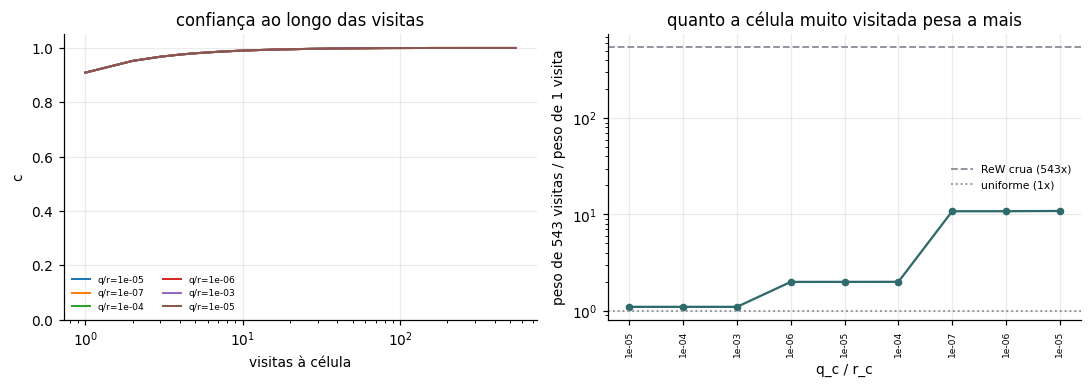

      q_c     r_c      n=1      n=6     n=20     n=64    n=271    n=543
-----------------------------------------------------------------------
    1e-06     0.1   0.9091   0.9836   0.9950   0.9985   0.9997   0.9999
    1e-06       1   0.5000   0.8571   0.9524   0.9846   0.9964   0.9982
    1e-06      10   0.0909   0.3750   0.6667   0.8649   0.9645   0.9820
    1e-05     0.1   0.9091   0.9836   0.9951   0.9985   0.9999   1.0000
    1e-05       1   0.5000   0.8572   0.9524   0.9847   0.9967   0.9988
    1e-05      10   0.0909   0.3750   0.6667   0.8650   0.9649   0.9828
   0.0001     0.1   0.9091   0.9837   0.9953   0.9992   1.0000   1.0000
   0.0001       1   0.5000   0.8573   0.9527   0.9856   0.9987   0.9999
   0.0001      10   0.0909   0.3751   0.6670   0.8660   0.9687   0.9886


In [131]:
def curva_c(q, r, p0, nmax):
    x, p, out = X0_C, p0, np.zeros(nmax + 1)
    for n in range(1, nmax + 1):
        pb = p + q; k = pb / (pb + r); x += k * (1.0 - x); p = (1.0 - k) * pb
        out[n] = x
    return out


VIS_EXEMPLO = [1, 6, 20, 64, 271, 543]
nmax = max(VIS_EXEMPLO)
n = np.arange(1, nmax + 1)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for q in GRID_Q_C:
    for r in [GRID_R_C[0], GRID_R_C[-1]]:
        ax[0].plot(n, curva_c(0.0001, 0.1, GRID_P0_C[-1], nmax)[1:], lw=1.3,
                   label=f"q/r={q/r:.0e}")
ax[0].set(xlabel="visitas à célula", ylabel="c", xscale="log", ylim=(0, 1.05),
          title="confiança ao longo das visitas")
ax[0].legend(frameon=False, fontsize=6, ncol=2)

razoes, rot = [], []
for q in GRID_Q_C:
    for r in GRID_R_C:
        c = curva_c(q, r, GRID_P0_C[-1], nmax)
        razoes.append(c[nmax] / c[1]); rot.append(f"{q/r:.0e}")
o = np.argsort(razoes)
ax[1].semilogy(range(len(razoes)), np.array(razoes)[o], "o-", color=COR_1, lw=1.5, ms=4)
ax[1].axhline(nmax, color=COR_REF, ls="--", lw=1.2, label=f"ReW crua ({nmax}x)")
ax[1].axhline(1.0, color=COR_REF, ls=":", lw=1.2, label="uniforme (1x)")
ax[1].set(xticks=range(len(razoes)), xticklabels=[rot[i] for i in o],
          xlabel="q_c / r_c", ylabel=f"peso de {nmax} visitas / peso de 1 visita",
          title="quanto a célula muito visitada pesa a mais")
ax[1].tick_params(axis="x", labelrotation=90, labelsize=6)
ax[1].legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()

print(f"{'q_c':>9}{'r_c':>8}" + "".join(f"{f'n={v}':>9}" for v in VIS_EXEMPLO))
print("-" * 71)
for q in GRID_Q_C:
    for r in GRID_R_C:
        c = curva_c(q, r, GRID_P0_C[-1], nmax)
        print(f"{q:>9g}{r:>8g}" + "".join(f"{c[v]:>9.4f}" for v in VIS_EXEMPLO))

---
# Seção 5 — Grid search

Busca conjunta: as **seis covariâncias e o tipo de média variam ao mesmo
tempo**. Os estados iniciais ficam fixos em zero.

Duas coisas que a busca sequencial anterior não fazia e que esta faz. Primeiro,
as seis covariâncias variam juntas, então o resultado é ótimo conjunto e não
ótimo por coordenada. Segundo, a média entra na busca: antes o MAE do grid era
sempre calculado com a aritmética ponderada, e o vencedor das covariâncias era
condicionado a essa escolha. Aqui o vencedor é o par (covariâncias, média), e
não existe agregação implícita.

A média age só no `predict`, então cada configuração de covariância é treinada
uma vez e as seis médias são lidas da mesma memória treinada. O resultado é
idêntico ao de um grid que retreinasse por média, e o custo é o das
covariâncias.

$3^6 = 729$ configurações por variante, três seeds cada, seis médias avaliadas
por ajuste.

## 5.0 A avaliação vetorizada

As médias em classe da seção 2.2 são a definição, e percorrem as 1494 RAM nodes
em laço Python. No grid isso é rodado $729 \times 3 \times 6$ vezes por variante
e domina o tempo.

Todas as seis se escrevem como reduções sobre matrizes $(n_{\text{teste}},
n_{\text{rams}})$, inclusive a mediana ponderada, que vira um `argsort` mais uma
soma acumulada. A célula abaixo faz isso e a seguinte confere contra as classes:
a diferença tem de ser de arredondamento e o padrão de NaN tem de ser o mesmo.

In [132]:
def coleta(modelo, slots):
    """(C, Y, V) de (n, n_rams) a partir dos slots do conjunto avaliado."""
    ok = slots >= 0
    s = np.where(ok, slots, 0)
    return modelo._C[s], modelo._Y[s], ok


def medias_vetorizadas(C, Y, V, nomes):
    """As seis médias ponderadas, em forma de redução sobre matrizes."""
    Cm = np.where(V, C, 0.0)
    sc = Cm.sum(1)
    ok = sc > 0
    V2 = V & (Y > 0)                       # harmônicas exigem y > 0
    Cm2 = np.where(V2, C, 0.0)
    sc2 = Cm2.sum(1)
    Yp = np.where(V2, Y, 1.0)              # só para dividir com segurança
    fin = lambda v, val: np.where(val, v, np.nan)
    out = {}

    if "KSimpleMean" in nomes:
        out["KSimpleMean"] = fin((Cm * Y).sum(1) / np.where(ok, sc, 1), ok)
    if "KPowerMean(2)" in nomes:
        out["KPowerMean(2)"] = fin(np.sqrt((Cm * Y ** 2).sum(1) / np.where(ok, sc, 1)), ok)
    if "KHarmonicMean" in nomes:
        s = (Cm2 / Yp).sum(1); o2 = s > 0
        out["KHarmonicMean"] = fin(sc2 / np.where(o2, s, 1), o2)
    if "KHarmonicPower(2)" in nomes:
        s = (Cm2 / Yp ** 2).sum(1); o2 = s > 0
        out["KHarmonicPower(2)"] = fin(np.sqrt(sc2 / np.where(o2, s, 1)), o2)
    if "KExponentialMean" in nomes:
        out["KExponentialMean"] = fin(np.log((Cm * np.exp(Y)).sum(1) / np.where(ok, sc, 1)), ok)
    if "KMedian" in nomes:
        o = np.argsort(Y, axis=1, kind="stable")
        Cs = np.take_along_axis(Cm, o, 1); Ys = np.take_along_axis(Y, o, 1)
        idx = (np.cumsum(Cs, axis=1) >= (sc / 2.0)[:, None]).argmax(1)
        out["KMedian"] = fin(Ys[np.arange(len(Y)), idx], ok)
    return out


IDX      = IndiceRK(RET_OBJ, ADDR_TR)
SLOTS_TE = IDX.slots(ADDR_TE)
print(f"IndiceRK do treino: {IDX.n_celulas:,} células ocupadas")
print("medias_vetorizadas definida")

IndiceRK do treino: 23,172 células ocupadas
medias_vetorizadas definida


In [133]:
# confere a vetorizada contra as classes da seção 2.2
_mod = RKalWeNN(ADDR, MAPPING, seed=0, indice=IDX).fit(y=y_train)
_C, _Y, _V = coleta(_mod, SLOTS_TE)
_vec = medias_vetorizadas(_C, _Y, _V, MEDIAS_NO_GRID)

print(f"{'média':<20}{'max|dif|':>12}{'NaN discordantes':>19}")
_falhas = 0
for _k in MEDIAS_NO_GRID:
    _m = medias_kal()[_k]
    _ref = np.array([_m.calculate(list(zip(_C[i][_V[i]], _Y[i][_V[i]])))
                     if _V[i].any() else np.nan for i in range(len(_C))])
    _a, _b = _vec[_k], _ref
    _amb = np.isfinite(_a) & np.isfinite(_b)
    _d = float(np.abs(_a[_amb] - _b[_amb]).max()) if _amb.any() else 0.0
    _mm = int((np.isfinite(_a) != np.isfinite(_b)).sum())
    _falhas += (_d > 1e-9 or _mm > 0)
    print(f"{_k:<20}{_d:>12.3e}{_mm:>19}")
print(f"\n{len(MEDIAS_NO_GRID)-_falhas}/{len(MEDIAS_NO_GRID)} conferem")

média                   max|dif|   NaN discordantes
KSimpleMean            4.796e-14                  0
KPowerMean(2)          2.309e-14                  0
KHarmonicMean          3.908e-14                  0
KHarmonicPower(2)      2.487e-14                  0
KExponentialMean       3.553e-15                  0
KMedian                0.000e+00                  0

6/6 conferem


In [134]:
def avalia(modelo, slots, y_ref, nomes):
    """Uma memória treinada, todas as médias. {nome: (MAE, RMSE, R2, nao_finito)}."""
    C, Y, V = coleta(modelo, slots)
    preds = medias_vetorizadas(C, Y, V, nomes)
    ss_tot = float(np.sum((y_ref - y_ref.mean()) ** 2))
    out = {}
    for nome, pr in preds.items():
        nao_fin = int((~np.isfinite(pr)).sum())
        if nao_fin:
            bons = pr[np.isfinite(pr)]
            pr = np.where(np.isfinite(pr), pr, bons.mean() if len(bons) else 0.0)
        out[nome] = (mean_absolute_error(y_ref, pr),
                     float(np.sqrt(mean_squared_error(y_ref, pr))),
                     1.0 - float(np.sum((y_ref - pr) ** 2)) / ss_tot,
                     nao_fin)
    return out


def grid_kalman(indice, slots_te, y_tr, y_te, grids, seeds=SEEDS_GRID,
                nomes=None, mostrar=True, x0_c=X0_C, x0_y=X0_Y,
                passo_predicao="visita"):
    """Grid conjunto das seis covariâncias, com a média variando junto.

    A média age só no predict, então cada configuração é treinada uma vez e
    todas as médias são lidas da mesma memória.
    """
    nomes = nomes or MEDIAS_NO_GRID
    combos = list(product(*grids))
    if mostrar:
        print(f"{len(combos)} covariâncias x {len(seeds)} seeds x {len(nomes)} médias")
    linhas, t0 = [], time.perf_counter()
    for n, (qc, rc, p0c, qy, ry, p0y) in enumerate(combos, 1):
        acum = {m: [] for m in nomes}
        for s in seeds:
            mod = RKalWeNN(indice.retina.address_size, indice.retina.mapping.ravel(),
                           q_c=qc, r_c=rc, p0_c=p0c, q_y=qy, r_y=ry, p0_y=p0y,
                           x0_c=x0_c, x0_y=x0_y, seed=s, indice=indice,
                           passo_predicao=passo_predicao).fit(y=y_tr)
            for nome, v in avalia(mod, slots_te, y_te, nomes).items():
                acum[nome].append(v)
        for nome, vs in acum.items():
            a = np.array([v[:3] for v in vs], dtype=float)
            linhas.append(dict(media=nome, q_c=qc, r_c=rc, p0_c=p0c,
                               q_y=qy, r_y=ry, p0_y=p0y,
                               MAE=a[:, 0].mean(), MAE_dp=a[:, 0].std(),
                               RMSE=a[:, 1].mean(), R2=a[:, 2].mean(),
                               nao_finito=int(max(v[3] for v in vs))))
        if mostrar and n % 50 == 0:
            el = time.perf_counter() - t0
            print(f"  {n:>3}/{len(combos)}   {el/60:.1f} min, "
                  f"faltam ~{el/n*(len(combos)-n)/60:.1f} min")
    g = pd.DataFrame(linhas).sort_values("MAE").reset_index(drop=True)
    if mostrar:
        print(f"concluído em {(time.perf_counter()-t0)/60:.1f} min")
    return g


print("avalia e grid_kalman definidos")

avalia e grid_kalman definidos


## 5.1 A busca

In [19]:
grid = grid_kalman(IDX, SLOTS_TE, y_train, y_test,
                   (GRID_Q_C, GRID_R_C, GRID_P0_C, GRID_Q_Y, GRID_R_Y, GRID_P0_Y))
MELHOR = grid.loc[0].to_dict()
print("\nVENCEDOR")
for c in ["media", "q_c", "r_c", "p0_c", "q_y", "r_y", "p0_y"]:
    print(f"  {c:<7} = {MELHOR[c]}")
print(f"  MAE  = {MELHOR['MAE']:.4f} ± {MELHOR['MAE_dp']:.4f}")
print(f"  RMSE = {MELHOR['RMSE']:.4f}   R2 = {MELHOR['R2']:.4f}")

[1] 729 covariâncias x 3 seeds x 6 médias = 13122 avaliações
   50/729   1.4 min, faltam ~18.9 min
  100/729   3.0 min, faltam ~18.6 min
  150/729   4.1 min, faltam ~15.7 min
  200/729   5.1 min, faltam ~13.6 min
  250/729   6.2 min, faltam ~11.8 min
  300/729   7.2 min, faltam ~10.3 min
  350/729   8.2 min, faltam ~8.9 min
  400/729   9.3 min, faltam ~7.6 min
  450/729   10.3 min, faltam ~6.4 min
  500/729   11.5 min, faltam ~5.3 min
  550/729   12.6 min, faltam ~4.1 min
  600/729   13.7 min, faltam ~2.9 min
  650/729   14.8 min, faltam ~1.8 min
  700/729   15.9 min, faltam ~0.7 min
[1] concluído em 16.5 min

VENCEDOR DA VARIANTE 1
  media   = HarmonicMean
  q_c     = 0.0001
  r_c     = 0.1
  p0_c    = 1.0
  q_y     = 0.0015
  r_y     = 1.0
  p0_y    = 1.0
  MAE  = 0.2467 ± 0.0061
  RMSE = 0.3322   R2 = 0.3309


## 5.2 As melhores configurações e o diagnóstico de borda

Vencedor num extremo de eixo indica faixa curta, não ótimo encontrado.

In [21]:
cols = ["media", "q_c", "r_c", "p0_c", "q_y", "r_y", "p0_y", "MAE", "MAE_dp", "R2"]
print("AS 12 MELHORES\n")
print(grid.head(12)[cols].to_string(index=False, float_format=lambda v: f"{v:.4g}"))
print(f"\nfaixa de MAE: {grid.MAE.min():.4f} a {grid.MAE.max():.4f}")
print(f"a menos de um desvio do vencedor: "
      f"{int((grid.MAE <= grid.loc[0,'MAE'] + grid.loc[0,'MAE_dp']).sum())} de {len(grid)}")

print("\nO vencedor caiu na borda de algum eixo?\n")
for nome, niveis in [("q_c", GRID_Q_C), ("r_c", GRID_R_C), ("p0_c", GRID_P0_C),
                     ("q_y", GRID_Q_Y), ("r_y", GRID_R_Y), ("p0_y", GRID_P0_Y)]:
    v = grid.loc[0, nome]
    onde = ("MENOR nível" if v == min(niveis)
            else "MAIOR nível" if v == max(niveis) else "interior")
    print(f"  {nome:<5} = {v:<10g} {onde}")
print(f"  média = {grid.loc[0,'media']}")

══ VARIANTE 1: as 10 melhores ══

           media    q_c  r_c  p0_c    q_y  r_y  p0_y    MAE   MAE_dp     R2
    HarmonicMean 0.0001  0.1     1 0.0015    1     1 0.2467 0.006149 0.3309
    HarmonicMean  1e-05  0.1     1 0.0015    1     1 0.2467 0.006149 0.3309
    HarmonicMean  1e-06  0.1     1 0.0015    1     1 0.2467 0.006149 0.3309
HarmonicPower(2) 0.0001  0.1     1 0.0015    1     1 0.2468 0.006392 0.3273
HarmonicPower(2)  1e-05  0.1     1 0.0015    1     1 0.2468 0.006392 0.3273
HarmonicPower(2)  1e-06  0.1     1 0.0015    1     1 0.2468 0.006392 0.3273
HarmonicPower(2) 0.0001  0.1   0.1 0.0015    1     1 0.2468 0.005893 0.3324
HarmonicPower(2)  1e-06    1     1 0.0015    1     1 0.2469 0.005891 0.3321
HarmonicPower(2) 0.0001    1     1 0.0015    1     1 0.2469  0.00589 0.3321
HarmonicPower(2)  1e-05  0.1   0.1 0.0015    1     1 0.2469  0.00589 0.3321

faixa de MAE: 0.2467 a 8.8486
a menos de um desvio do vencedor: 434 de 4374

══ VARIANTE B: as 10 melhores ══

           media  

## 5.3 Qual média venceu

O melhor MAE de cada média, para ver se a escolha da agregação muda o resultado
ou se todas empatam.

MELHOR MAE POR MÉDIA (escala log1p)

                  variante 1  variante B
media                                   
HarmonicMean          0.2467      0.2837
HarmonicPower(2)      0.2468      0.2821
SimpleMean            0.2472      0.2849
PowerMean(2)          0.2474      0.2852
ExponentialMean       0.2487      0.2864
Median                0.2737      0.3028


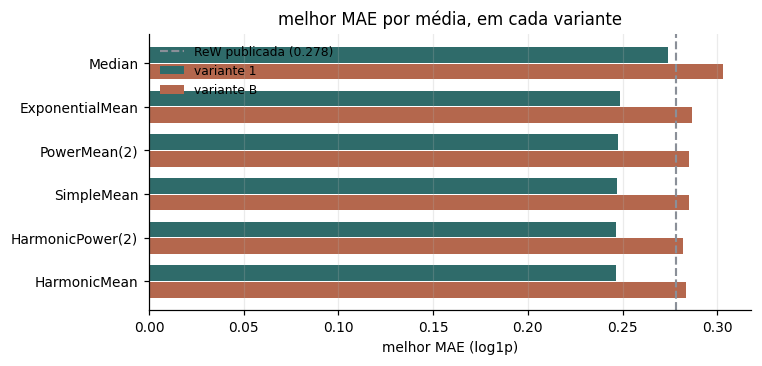

In [22]:
tab = grid.groupby("media").MAE.min().sort_values()
print("MELHOR MAE POR MÉDIA (escala log1p)\n")
print(tab.to_string(float_format=lambda v: f"{v:.4f}"))

fig, ax = plt.subplots(figsize=(6.5, 3.2))
o = tab.sort_values(ascending=False)
ax.barh(np.arange(len(o)), o.values, color=COR_1, height=.6)
ax.axvline(REF_ARTIGO, color=COR_REF, ls="--", lw=1.4, label=f"ReW publicada ({REF_ARTIGO})")
ax.set(yticks=np.arange(len(o)), yticklabels=o.index, xlabel="melhor MAE (log1p)",
       title="melhor MAE por média")
ax.grid(axis="y", visible=False); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

---
# Seção 6 — Resultado contra a referência publicada

O baseline é o MAE 0.278 da Tabela 2 do Neurocomputing 416 (2020), ReW no House
Prices com a `Median`. A Regression WiSARD não é reexecutada aqui: o número
publicado passou por revisão por pares e é o que a comparação precisa.

In [23]:
mem = []
for s in SEEDS_GRID:
    mod = RKalWeNN(ADDR, MAPPING, q_c=MELHOR["q_c"], r_c=MELHOR["r_c"],
                   p0_c=MELHOR["p0_c"], q_y=MELHOR["q_y"], r_y=MELHOR["r_y"],
                   p0_y=MELHOR["p0_y"], x0_c=X0_C, x0_y=X0_Y, seed=s,
                   indice=IDX).fit(y=y_train)
    mem.append(mod.memoria_bytes())

final = pd.DataFrame([{"modelo": "R-KalWeNN", "media": MELHOR["media"],
                       "MAE": MELHOR["MAE"], "MAE_dp": MELHOR["MAE_dp"],
                       "RMSE": MELHOR["RMSE"], "R2": MELHOR["R2"],
                       "memoria_KB": np.mean(mem) / 1024}])
print(final.to_string(index=False, float_format=lambda v: f"{v:,.4f}"))
print(f"\nreferência publicada (ReW, Median, Neurocomputing 416): MAE {REF_ARTIGO:.3f}")
print(f"R-KalWeNN contra a referência: "
      f"{(MELHOR['MAE']/REF_ARTIGO - 1)*100:+.1f}% de MAE")

     modelo            media    MAE  MAE_dp   RMSE     R2  memoria_KB
R-KalWeNN-1     HarmonicMean 0.2467  0.0061 0.3322 0.3309    905.1562
R-KalWeNN-B HarmonicPower(2) 0.2821  0.0025 0.3738 0.1532  3,169.0312

referência publicada (ReW, Median, Neurocomputing 416): MAE 0.278

  R-KalWeNN-1 contra a referência: -11.3% de MAE
  R-KalWeNN-B contra a referência: +1.5% de MAE


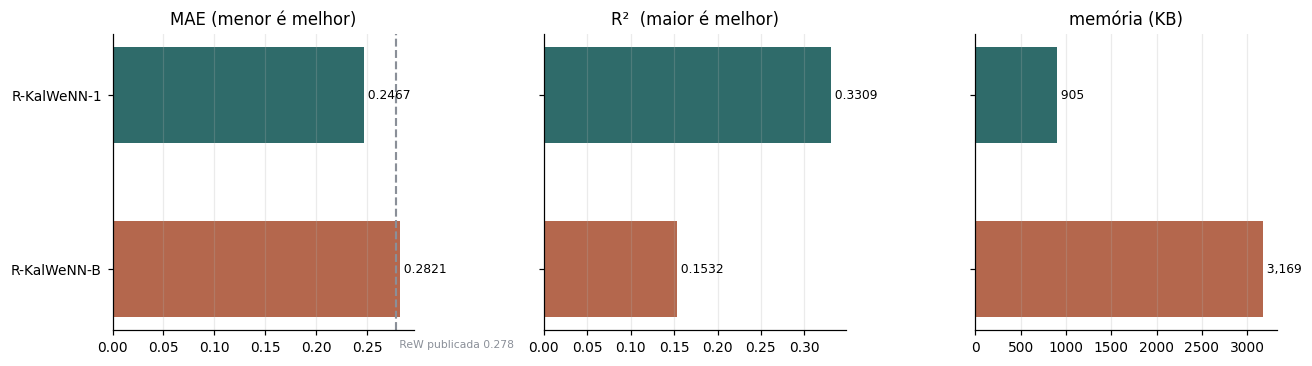

In [24]:
fig, ax = plt.subplots(figsize=(6.5, 2.6))
nomes = ["chutar a média", f"ReW publicada", "R-KalWeNN"]
vals  = [mae_media, REF_ARTIGO, MELHOR["MAE"]]
cores = [COR_REF, COR_REF, COR_1]
o = np.argsort(vals)[::-1]
ax.barh(np.arange(3), [vals[i] for i in o], color=[cores[i] for i in o], height=.6)
ax.set(yticks=np.arange(3), yticklabels=[nomes[i] for i in o],
       xlabel="MAE (log1p)", title="R-KalWeNN contra as referências")
ax.grid(axis="y", visible=False)
for i, v in enumerate([vals[j] for j in o]):
    ax.text(v, i, f" {v:.4f}", va="center", fontsize=8)
plt.tight_layout(); plt.show()

---
# Seção 7 — Teste rápido: regressão linear

Fora do escopo do R-KalWeNN, só para ter mais um ponto de referência.

Mesmo split, mesmos 332 atributos e mesmo alvo em `log1p`, então o MAE é
diretamente comparável ao das seções anteriores. A entrada é a matriz numérica
da seção 3.4, antes da binarização: a regressão linear usa os valores contínuos,
enquanto a ReW e o R-KalWeNN usam a versão em thermometer.

Dois avisos para a leitura do número. São 332 atributos para 973 exemplos de
treino, muitos deles colunas de one-hot correlacionadas, então mínimos quadrados
sem regularização tende a ajustar demais o treino. E o pipeline da seção 3
concatena treino e teste antes de imputar, o que vaza informação do teste para a
regressão linear do mesmo jeito que vaza para os outros modelos.

REGRESSÃO LINEAR (escala log1p)

                MAE     RMSE       R2
  treino     0.2264   0.3005   0.4125
  teste      0.2318   0.3040   0.4400

  posto da matriz de treino: 2 de 332 colunas, com 973 linhas


PONTOS DE REFERÊNCIA, todos em MAE sobre o mesmo teste

  regressão linear             0.2318
  R-KalWeNN-1                  0.2467
  ReW publicada (Median)       0.2780
  R-KalWeNN-B                  0.2821
  chutar a média do treino     0.3151


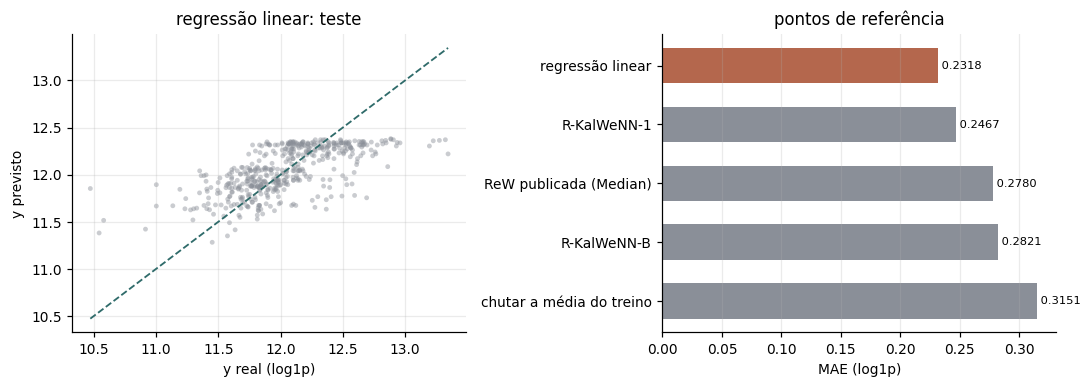

In [102]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression().fit(X_train, y_train)
p_tr, p_te = lr.predict(X_train), lr.predict(X_test)

def metricas(y_true, y_pred):
    ss_tot = float(np.sum((y_true - y_true.mean()) ** 2))
    return (mean_absolute_error(y_true, y_pred),
            float(np.sqrt(mean_squared_error(y_true, y_pred))),
            1.0 - float(np.sum((y_true - y_pred) ** 2)) / ss_tot)

mae_tr, rmse_tr, r2_tr = metricas(y_train, p_tr)
mae_te, rmse_te, r2_te = metricas(y_test, p_te)

print("REGRESSÃO LINEAR (escala log1p)\n")
print(f"  {'':8}{'MAE':>9}{'RMSE':>9}{'R2':>9}")
print(f"  {'treino':<8}{mae_tr:>9.4f}{rmse_tr:>9.4f}{r2_tr:>9.4f}")
print(f"  {'teste':<8}{mae_te:>9.4f}{rmse_te:>9.4f}{r2_te:>9.4f}")
print(f"\n  posto da matriz de treino: {np.linalg.matrix_rank(X_train)} "
      f"de {X_train.shape[1]} colunas, com {len(X_train)} linhas")

print("\n\nPONTOS DE REFERÊNCIA, todos em MAE sobre o mesmo teste\n")
ref = [("chutar a média do treino", mae_media),
       ("ReW publicada (Median)", REF_ARTIGO),
       ("regressão linear", mae_te)]
if "final" in globals():
    ref += [(r.modelo, r.MAE) for _, r in final.iterrows()]
for nome, v in sorted(ref, key=lambda t: t[1]):
    print(f"  {nome:<28} {v:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].scatter(y_test, p_te, s=10, alpha=.45, color=COR_REF, edgecolor="none")
lims = [min(y_test.min(), p_te.min()), max(y_test.max(), p_te.max())]
ax[0].plot(lims, lims, ls="--", lw=1.2, color=COR_1)
ax[0].set(xlabel="y real (log1p)", ylabel="y previsto", title="regressão linear: teste")

nomes = [n for n, _ in sorted(ref, key=lambda t: t[1], reverse=True)]
vals  = [v for _, v in sorted(ref, key=lambda t: t[1], reverse=True)]
cores = [COR_B if n == "regressão linear" else COR_REF for n in nomes]
ax[1].barh(np.arange(len(nomes)), vals, color=cores, height=.6)
ax[1].set(yticks=np.arange(len(nomes)), yticklabels=nomes, xlabel="MAE (log1p)",
          title="pontos de referência")
ax[1].grid(axis="y", visible=False)
for i, v in enumerate(vals):
    ax[1].text(v, i, f" {v:.4f}", va="center", fontsize=7.5)
plt.tight_layout(); plt.show()

---
# Seção 8 — Varredura completa

Até aqui a codificação esteve congelada em thermometer 27 e address size 6, que
é a configuração escolhida para reproduzir o número publicado da ReW. Ela não é
necessariamente a melhor para o R-KalWeNN: o filtro muda quem pesa quanto na
agregação, e o regime de colisão depende justamente do address size.

Com address 6 existem só 64 endereços por RAM node e 973 exemplos colidem muito:
a célula mais visitada recebe 543 dos 973. É o regime de colisão máxima, que é
onde a ponderação por contador mais atrapalha e onde o filtro do peso mais tem o
que corrigir. Com address grande as células ficam esparsas e o filtro tem menos
o que fazer.

Esta seção varre os quatro eixos ao mesmo tempo: **thermometer size, address
size, as seis covariâncias do Kalman e o tipo de média**.

## 8.1 Os eixos da busca

Todos os parâmetros da varredura estão na célula abaixo, separados dos da seção
1 pelo prefixo `SW_`, para poderem ser mexidos sem afetar as seções anteriores.

O `SW_Q_Y` ganhou o nível $1{,}5\cdot10^{-2}$, que faltava entre
$1{,}5\cdot10^{-3}$ e $1{,}5\cdot10^{-1}$. Sob o passo de predição por visita, é
nessa faixa que o ganho de regime cai entre 0,03 e 0,35, ou seja, onde o filtro
opera. Como o modo é amostrado com orçamento fixo, acrescentar nível não muda o
tempo, só o espaço de onde as configurações são sorteadas.

Os address sizes seguem o critério do `houseprice.py`: todos os divisores do
tamanho da retina, porque a retina precisa ser dividida em RAM nodes de tamanho
igual sem sobrar bit. O teto de 62 bits existe porque o endereço é montado em
inteiro de 64 bits e acima disso o índice estoura.

O custo de um ajuste é proporcional ao número de RAM nodes, que é
retina dividida por address size. Então **address size maior sai mais barato**,
e o eixo caro é o thermometer.

In [156]:
# ═══════════════════ EIXOS DA VARREDURA ══════════════════════════════════════
# Autossuficiente: os valores estão escritos aqui, não vêm da seção 1.
# Mexa só nesta célula e rode a 8.2 para ver o custo.

# ── codificação ──────────────────────────────────────────────────────────────
SW_THERM      = list(range(5, 31))   # bits de thermometer por atributo
SW_ADDR_MIN   =  4                    # menor address size aceito
SW_ADDR_MAX   =  4                   # 2^63 estoura o inteiro de 64 bits
SW_ADDR_LISTA = None                  # None = divisores da retina; ou uma lista

# ── filtro do peso c   (observação z = 1 no acesso, estado em [0,1)) ─────────
SW_Q_C  = [1e-6, 1e-5, 1e-4]
SW_R_C  = [1e-1, 1.0, 10.0]
SW_P0_C = [1e-2, 1e-1, 1.0]

# ── filtro da estimativa y   (observação z = y_i, estado ~ 12 em log1p) ──────
SW_Q_Y  = [1.5e-3, 1.5e-2, 1.5e-1, 1.5]
SW_R_Y  = [0.5, 1.0]
SW_P0_Y = [0.01, 0.5, 1.0]

# ── estados iniciais, médias, repetições ─────────────────────────────────────
SW_X0_C, SW_X0_Y = 0.0, 0.0
SW_PASSO_PREDICAO = "visita"          # "visita" = q_y por acesso (seção 4.1)
                                      # "exemplo" = q_y por exemplo do treino
SW_MEDIAS = ["KSimpleMean", "KPowerMean(2)", "KHarmonicMean",
             "KHarmonicPower(2)", "KExponentialMean", "KMedian"]
SW_SEEDS  = (0, 1)

# ── orçamento ────────────────────────────────────────────────────────────────
#   "completo"  enumera o produto cartesiano inteiro
#   "amostrado" sorteia SW_ORCAMENTO configurações do produto, sem repetir
SW_MODO         = "amostrado"
SW_ORCAMENTO    = 1500
SW_SEED_AMOSTRA = 0
SW_ARQUIVO      = "varredura_rkalwenn.csv"


# ═══════════════════ o que isso gera ═════════════════════════════════════════
def divisores(v, lo=SW_ADDR_MIN, hi=SW_ADDR_MAX):
    """Divisores de v em [lo, hi], mais v se couber. Como o allDividers do
    houseprice.py, com teto para o índice de 64 bits não estourar."""
    d = [i for i in range(lo, int(v / 2) + 1) if v % i == 0 and i <= hi]
    return d + ([v] if lo <= v <= hi else [])


PARES = [(t, a) for t in SW_THERM
         for a in (SW_ADDR_LISTA if SW_ADDR_LISTA is not None
                   else divisores(t * N_ATRIB))]
N_KAL = (len(SW_Q_C) * len(SW_R_C) * len(SW_P0_C) *
         len(SW_Q_Y) * len(SW_R_Y) * len(SW_P0_Y))

print(f"passo de predição do filtro de y: {SW_PASSO_PREDICAO!r}\n")
print("EIXOS EM USO\n")
for nome, val in [("thermometer", SW_THERM), ("q_c", SW_Q_C), ("r_c", SW_R_C),
                  ("p0_c", SW_P0_C), ("q_y", SW_Q_Y), ("r_y", SW_R_Y),
                  ("p0_y", SW_P0_Y), ("médias", SW_MEDIAS), ("seeds", list(SW_SEEDS))]:
    s = str(val)
    print(f"  {nome:<12} {len(val):>2} níveis   {s if len(s) < 62 else s[:59] + '...'}")
_addr_txt = (f"divisores da retina em [{SW_ADDR_MIN}, {SW_ADDR_MAX}]"
             if SW_ADDR_LISTA is None else str(SW_ADDR_LISTA))
print(f"  {'address':<12}            {_addr_txt}")
print(f"  {'x0_c, x0_y':<12}            {SW_X0_C}, {SW_X0_Y}")

# só as razões definem o modelo, então níveis diferentes podem ser o mesmo ponto
raz_c = {(round(p / r, 12), round(q / r, 12))
         for q in SW_Q_C for r in SW_R_C for p in SW_P0_C}
raz_y = {(round(p / r, 12), round(q / r, 12))
         for q in SW_Q_Y for r in SW_R_Y for p in SW_P0_Y}
dist = len(raz_c) * len(raz_y)

print(f"\nRAZÕES COBERTAS  (com x0 = 0, o modelo depende só de q/r e p0/r)\n")
print(f"  q_c/r_c   {sorted({round(q/r, 12) for q in SW_Q_C for r in SW_R_C})}")
print(f"  p0_c/r_c  {sorted({round(p/r, 12) for p in SW_P0_C for r in SW_R_C})}")
print(f"  q_y/r_y   {sorted({round(q/r, 12) for q in SW_Q_Y for r in SW_R_Y})}")
print(f"  p0_y/r_y  {sorted({round(p/r, 12) for p in SW_P0_Y for r in SW_R_Y})}")
print(f"\n  {N_KAL} pontos do grid -> {dist} modelos distintos "
      f"({100*(1-dist/N_KAL):.0f}% duplicatas exatas)")

# o que cada razão q/r produz de ganho de regime, que é o que o filtro faz
def _kappa_regime(razao, n=4000):
    p = 1.0
    for _ in range(n):
        pb = p + razao; k = pb / (pb + 1.0); p = (1.0 - k) * pb
    return k

print(f"\nGANHO DE REGIME kappa = f(q/r), que é o que o filtro de fato faz\n")
print(f"  {'q_y/r_y':>12}{'kappa':>10}{'janela':>10}   regime")
for r_ in sorted({round(q / r, 12) for q in SW_Q_Y for r in SW_R_Y}):
    k = _kappa_regime(r_)
    reg = ("congelado" if k < 0.02 else "desligado" if k > 0.6 else "opera")
    print(f"  {r_:>12.3g}{k:>10.4f}{1/k:>10.1f}   {reg}")

print(f"\nTAMANHO\n")
print(f"  pares (thermometer, address) : {len(PARES)}")
print(f"  covariâncias                 : {N_KAL}")
print(f"  produto completo             : {len(PARES)*N_KAL:,} configurações"
      f" = {len(PARES)*N_KAL*len(SW_SEEDS):,} ajustes")
print(f"  modo                         : {SW_MODO}"
      + (f", orçamento {SW_ORCAMENTO:,}" if SW_MODO == "amostrado" else ""))
print(f"  médias                       : de graça, lidas do mesmo ajuste")

passo de predição do filtro de y: 'visita'

EIXOS EM USO

  thermometer  26 níveis   [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20,...
  q_c           3 níveis   [1e-06, 1e-05, 0.0001]
  r_c           3 níveis   [0.1, 1.0, 10.0]
  p0_c          3 níveis   [0.01, 0.1, 1.0]
  q_y           4 níveis   [0.0015, 0.015, 0.15, 1.5]
  r_y           2 níveis   [0.5, 1.0]
  p0_y          3 níveis   [0.01, 0.5, 1.0]
  médias        6 níveis   ['KSimpleMean', 'KPowerMean(2)', 'KHarmonicMean', 'KHarmoni...
  seeds         2 níveis   [0, 1]
  address                 divisores da retina em [4, 4]
  x0_c, x0_y              0.0, 0.0

RAZÕES COBERTAS  (com x0 = 0, o modelo depende só de q/r e p0/r)

  q_c/r_c   [1e-07, 1e-06, 1e-05, 0.0001, 0.001]
  p0_c/r_c  [0.001, 0.01, 0.1, 1.0, 10.0]
  q_y/r_y   [0.0015, 0.003, 0.015, 0.03, 0.15, 0.3, 1.5, 3.0]
  p0_y/r_y  [0.01, 0.02, 0.5, 1.0, 2.0]

  648 pontos do grid -> 456 modelos distintos (30% duplicatas exatas)

GANHO DE REGIME kappa = f(q/r),

## 8.2 Estimativa de custo, antes de rodar

Mede um ajuste em três pares (thermometer, address) de tamanhos diferentes e
extrapola pelo número de RAM nodes, que é o que domina. Rode esta célula antes
da busca para saber no que está se metendo.

In [157]:
def custo_por_ram_node():
    """Segundos por RAM node por ajuste, medido em três tamanhos."""
    amostras = []
    for t, a in [PARES[0], PARES[len(PARES)//2], PARES[-1]]:
        dt = DynamicThermometer([t]*N_ATRIB, mins, maxs)
        Xb = dt.transform(X_train)
        ret = Retina(a, sorteia_mapping(Xb.shape[1], a, seed=SEED_MAPPING))
        idx = IndiceRK(ret, ret.enderecos(Xb))
        t0 = time.perf_counter()
        RKalWeNN(a, ret.mapping.ravel(), indice=idx, seed=0, x0_c=SW_X0_C,
                 x0_y=SW_X0_Y, passo_predicao=SW_PASSO_PREDICAO).fit(y=y_train)
        amostras.append(((time.perf_counter()-t0) / ret.n_rams, ret.n_rams, t, a))
    return float(np.median([s[0] for s in amostras])), amostras


seg_por_ram, amostras = custo_por_ram_node()
print("medições:")
for s, nr, t, a in amostras:
    print(f"  therm {t:>2}, address {a:>4} -> {nr:>5} RAM nodes, "
          f"{s*nr:.3f} s por ajuste")

rams_total = sum(t * N_ATRIB // a for t, a in PARES)
n_cfg = len(PARES) * N_KAL if SW_MODO == "completo" else min(SW_ORCAMENTO, len(PARES)*N_KAL)
frac = n_cfg / (len(PARES) * N_KAL)
seg = rams_total * N_KAL * frac * len(SW_SEEDS) * seg_por_ram

fim = time.strftime("%d/%m %H:%M", time.localtime(time.time() + seg))
print(f"\nestimativa para {n_cfg:,} configurações x {len(SW_SEEDS)} seeds:")
print(f"  {seg/60:,.0f} min  ({seg/3600:,.1f} h)")
print(f"  começando agora, termina por volta de {fim}")

seg_completo = rams_total * N_KAL * len(SW_SEEDS) * seg_por_ram
print(f"\nproduto completo ({len(PARES)*N_KAL:,} configurações): "
      f"{seg_completo/3600:,.0f} h")
print("\nAjuste SW_ORCAMENTO, SW_THERM ou os níveis das covariâncias e rode de novo.")

medições:
  therm  5, address    4 ->   415 RAM nodes, 0.322 s por ajuste
  therm 18, address    4 ->  1494 RAM nodes, 1.097 s por ajuste
  therm 30, address    4 ->  2490 RAM nodes, 0.554 s por ajuste

estimativa para 1,500 configurações x 2 seeds:
  53 min  (0.9 h)
  começando agora, termina por volta de 27/08 15:13

produto completo (16,848 configurações): 10 h

Ajuste SW_ORCAMENTO, SW_THERM ou os níveis das covariâncias e rode de novo.


## 8.3 A busca

Grava um CSV parcial a cada par (thermometer, address), então dá para
interromper e retomar a leitura do que já rodou.

A binarização é refeita uma vez por thermometer e o índice uma vez por par
(thermometer, address); as covariâncias e as médias reaproveitam os dois.

In [158]:
combos_kal = list(product(SW_Q_C, SW_R_C, SW_P0_C, SW_Q_Y, SW_R_Y, SW_P0_Y))
rng_am = np.random.default_rng(SW_SEED_AMOSTRA)

if SW_MODO == "amostrado":
    todos = [(p, k) for p in range(len(PARES)) for k in range(len(combos_kal))]
    escolha = rng_am.choice(len(todos), size=min(SW_ORCAMENTO, len(todos)), replace=False)
    plano = {}
    for e in escolha:
        ip, ik = todos[e]
        plano.setdefault(ip, []).append(ik)
else:
    plano = {ip: list(range(len(combos_kal))) for ip in range(len(PARES))}

n_total = sum(len(v) for v in plano.values())

# O custo de um ajuste é proporcional ao número de RAM nodes, que varia de
# dezenas a milhares entre os pares. Extrapolar por contagem de configurações
# daria previsão errada, então o progresso é medido em RAM nodes ajustados.
def rams_do_par(ip):
    t, a = PARES[ip]
    return t * N_ATRIB // a

trabalho_total = sum(rams_do_par(ip) * len(v) * len(SW_SEEDS)
                     for ip, v in plano.items())

print(f"passo de predição do filtro de y: {SW_PASSO_PREDICAO!r}")
print(f"{n_total:,} configurações em {len(plano)} pares (thermometer, address)")
print(f"trabalho total: {trabalho_total:,} ajustes de RAM node\n")

with open(SW_ARQUIVO, "w") as f:
    f.write("therm,address,n_rams,media,q_c,r_c,p0_c,q_y,r_y,p0_y,"
            "MAE,MAE_dp,RMSE,R2,nao_finito\n")

linhas, feitas, trabalho_feito, t0 = [], 0, 0, time.perf_counter()
therm_atual, Xb_tr_s, Xb_te_s = None, None, None

for ip in sorted(plano):
    t, a = PARES[ip]
    if t != therm_atual:                                   # binariza uma vez por therm
        dt = DynamicThermometer([t] * N_ATRIB, mins, maxs)
        Xb_tr_s, Xb_te_s = dt.transform(X_train), dt.transform(X_test)
        therm_atual = t
    ret = Retina(a, sorteia_mapping(Xb_tr_s.shape[1], a, seed=SEED_MAPPING))
    idx = IndiceRK(ret, ret.enderecos(Xb_tr_s))
    sl_te = idx.slots(ret.enderecos(Xb_te_s))

    for ik in plano[ip]:
        qc, rc, p0c, qy, ry, p0y = combos_kal[ik]
        g = grid_kalman(idx, sl_te, y_train, y_test,
                        ([qc], [rc], [p0c], [qy], [ry], [p0y]),
                        seeds=SW_SEEDS, nomes=SW_MEDIAS, mostrar=False,
                        x0_c=SW_X0_C, x0_y=SW_X0_Y,
                        passo_predicao=SW_PASSO_PREDICAO)
        g.insert(0, "n_rams", ret.n_rams); g.insert(0, "address", a); g.insert(0, "therm", t)
        linhas.append(g)
        with open(SW_ARQUIVO, "a") as f:
            for _, r in g.iterrows():
                f.write(f"{t},{a},{ret.n_rams},{r.media},{r.q_c},{r.r_c},{r.p0_c},"
                        f"{r.q_y},{r.r_y},{r.p0_y},{r.MAE:.6f},{r.MAE_dp:.6f},"
                        f"{r.RMSE:.6f},{r.R2:.6f},{int(r.nao_finito)}\n")
        feitas += 1
        trabalho_feito += ret.n_rams * len(SW_SEEDS)

    el = time.perf_counter() - t0
    restante = el * (trabalho_total - trabalho_feito) / max(trabalho_feito, 1)
    fim = time.strftime("%H:%M", time.localtime(time.time() + restante))
    print(f"  therm {t:>2} address {a:>4} ({ret.n_rams:>5} rams)  "
          f"{feitas:>5}/{n_total} cfg  {100*trabalho_feito/trabalho_total:>5.1f}% "
          f"do trabalho  |  {el/60:>5.1f} min corridos, "
          f"faltam ~{restante/60:>5.0f} min, término ~{fim}")

varredura = pd.concat(linhas, ignore_index=True).sort_values("MAE").reset_index(drop=True)
_tot = time.perf_counter() - t0
print(f"\nconcluído em {_tot/60:.1f} min ({_tot/3600:.2f} h), "
      f"{len(varredura):,} linhas gravadas em {SW_ARQUIVO}")
print(f"média de {_tot/max(feitas,1):.2f} s por configuração "
      f"({1e3*_tot/max(trabalho_feito,1):.3f} ms por ajuste de RAM node)")

passo de predição do filtro de y: 'visita'
1,500 configurações em 26 pares (thermometer, address)
trabalho total: 4,421,576 ajustes de RAM node

  therm  5 address    4 (  415 rams)     47/1500 cfg    0.9% do trabalho  |    0.2 min corridos, faltam ~   21 min, término ~14:41
  therm  6 address    4 (  498 rams)    101/1500 cfg    2.1% do trabalho  |    0.4 min corridos, faltam ~   19 min, término ~14:39
  therm  7 address    4 (  581 rams)    154/1500 cfg    3.5% do trabalho  |    0.6 min corridos, faltam ~   18 min, término ~14:38
  therm  8 address    4 (  664 rams)    207/1500 cfg    5.1% do trabalho  |    1.0 min corridos, faltam ~   18 min, término ~14:38
  therm  9 address    4 (  747 rams)    272/1500 cfg    7.3% do trabalho  |    1.3 min corridos, faltam ~   17 min, término ~14:38
  therm 10 address    4 (  830 rams)    325/1500 cfg    9.3% do trabalho  |    1.6 min corridos, faltam ~   16 min, término ~14:37
  therm 11 address    4 (  913 rams)    378/1500 cfg   11.5% do traba

## 8.4 Resultado

Os eixos do filtro são as razões $q/r$ e $p_0/r$, e não $q$, $r$ e $p_0$
separados: com os estados iniciais em zero, dois pontos com as mesmas razões são
o mesmo modelo. O número de RAM nodes entra no lugar do address size, porque a
grade thermometer × address só tem 16% das células preenchidas.

 therm  address  n_rams             media    q_c  r_c  p0_c    q_y  r_y  p0_y    MAE   MAE_dp     R2
    20        4    1660 KHarmonicPower(2) 0.0001    1     1 0.0015  0.5   0.5 0.2621 0.005879 0.2542
     9        4     747 KHarmonicPower(2)  1e-06  0.1     1 0.0015  0.5     1 0.2623 0.004863 0.2627
    20        4    1660     KHarmonicMean 0.0001    1     1 0.0015  0.5   0.5 0.2624 0.005514 0.2551
     9        4     747 KHarmonicPower(2) 0.0001  0.1   0.1 0.0015  0.5   0.5 0.2625 0.006112  0.254
    16        4    1328 KHarmonicPower(2)  1e-05  0.1     1 0.0015  0.5     1 0.2625 0.004854 0.2634
    20        4    1660 KHarmonicPower(2)  1e-06    1     1 0.0015    1     1 0.2625 0.005837 0.2486
     9        4     747     KHarmonicMean 0.0001  0.1   0.1 0.0015  0.5   0.5 0.2626 0.005772 0.2547
    27        4    2241 KHarmonicPower(2) 0.0001  0.1     1 0.0015  0.5     1 0.2626 0.004739  0.262
    11        4     913     KHarmonicMean  1e-05  0.1   0.1 0.0015  0.5   0.5 0.2627 0.0057

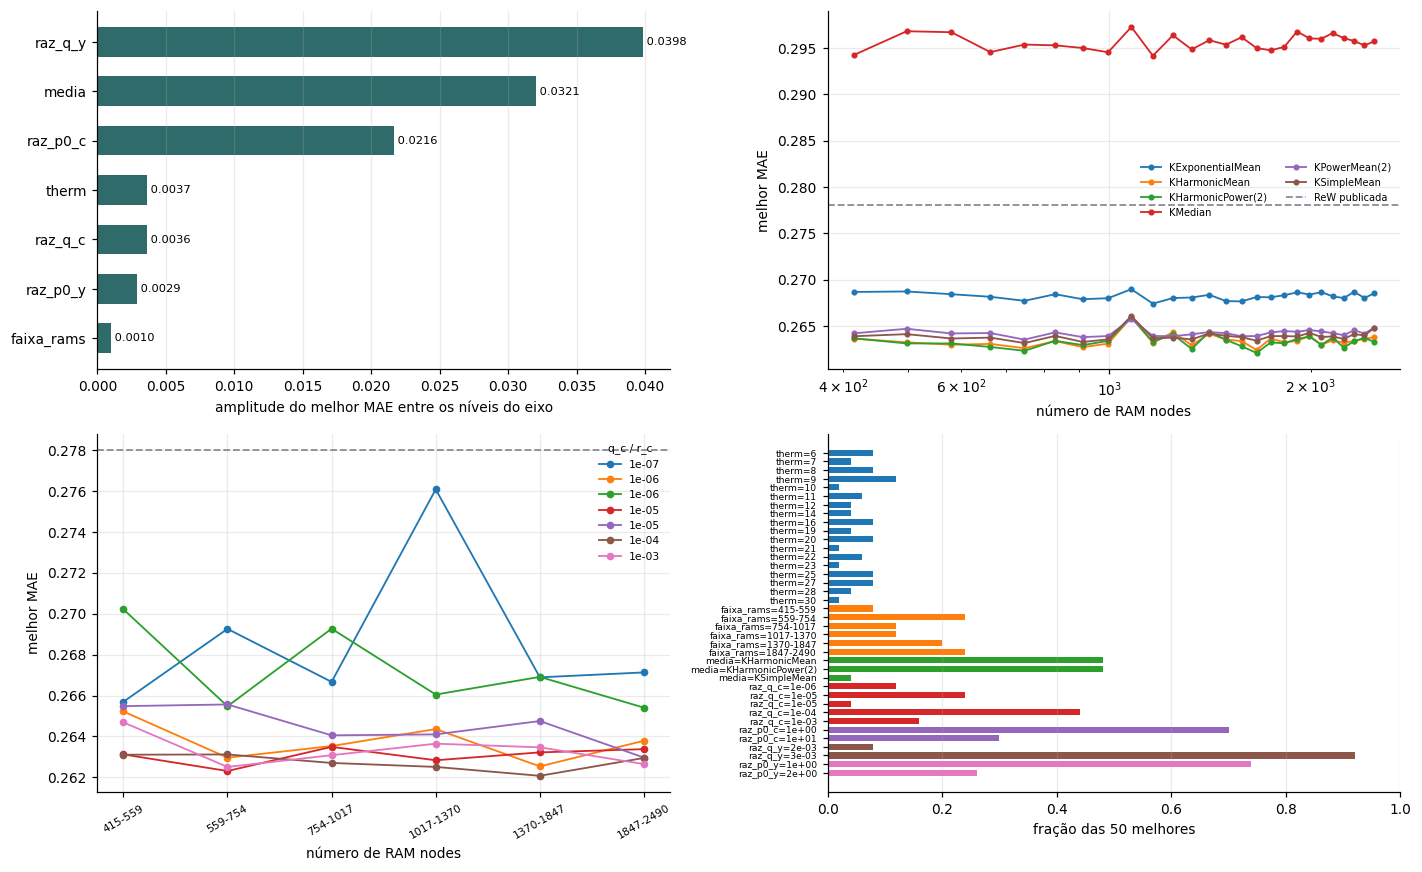

In [160]:
if "varredura" not in globals():
    varredura = pd.read_csv(SW_ARQUIVO).sort_values("MAE").reset_index(drop=True)

v = varredura.copy()
v["raz_q_c"]  = v.q_c / v.r_c
v["raz_p0_c"] = v.p0_c / v.r_c
v["raz_q_y"]  = v.q_y / v.r_y
v["raz_p0_y"] = v.p0_y / v.r_y

bins = np.unique(np.geomspace(v.n_rams.min(), v.n_rams.max(), 7).round().astype(int))
v["faixa_rams"] = pd.cut(v.n_rams, bins=bins, include_lowest=True,
                         labels=[f"{bins[i]}-{bins[i+1]}" for i in range(len(bins)-1)])

EIXOS = ["therm", "faixa_rams", "media", "raz_q_c", "raz_p0_c", "raz_q_y", "raz_p0_y"]
TOPK = min(50, len(v))
top = v.nsmallest(TOPK, "MAE")

cols = ["therm", "address", "n_rams", "media", "q_c", "r_c", "p0_c",
        "q_y", "r_y", "p0_y", "MAE", "MAE_dp", "R2"]
print(v.head(10)[cols].to_string(index=False, float_format=lambda x: f"{x:.4g}"))
b = v.loc[0]
print(f"\nmelhor: therm {int(b.therm)}, address {int(b.address)}, "
      f"{int(b.n_rams)} rams, {b.media}, MAE {b.MAE:.4f} ± {b.MAE_dp:.4f}, R2 {b.R2:.4f}")
print(f"ReW publicada: MAE {REF_ARTIGO:.3f}   |   {len(v):,} linhas na varredura")

fig, ax = plt.subplots(2, 2, figsize=(13, 8))

# 1 ── amplitude do melhor MAE por eixo
amp = {}
for e in EIXOS:
    m = v.groupby(e, observed=True).MAE.min()
    amp[e] = float(m.max() - m.min()) if len(m) > 1 else 0.0
amp = pd.Series(amp).sort_values()
ax[0, 0].barh(np.arange(len(amp)), amp.values, color=COR_1, height=.6)
ax[0, 0].set(yticks=np.arange(len(amp)), yticklabels=amp.index,
             xlabel="amplitude do melhor MAE entre os níveis do eixo")
ax[0, 0].grid(axis="y", visible=False)
for i, val in enumerate(amp.values):
    ax[0, 0].text(val, i, f" {val:.4f}", va="center", fontsize=7.5)

# 2 ── melhor MAE por número de RAM nodes, uma linha por média
piv = v.groupby(["n_rams", "media"], observed=True).MAE.min().unstack()
for m in piv.columns:
    s = piv[m].dropna()
    ax[0, 1].plot(s.index, s.values, "o-", lw=1.2, ms=3, label=m)
ax[0, 1].axhline(REF_ARTIGO, color=COR_REF, ls="--", lw=1.2, label="ReW publicada")
ax[0, 1].set(xscale="log", xlabel="número de RAM nodes", ylabel="melhor MAE")
ax[0, 1].legend(frameon=False, fontsize=6.5, ncol=2)

# 3 ── melhor MAE por número de RAM nodes, uma linha por q_c/r_c
piv2 = v.groupby(["faixa_rams", "raz_q_c"], observed=True).MAE.min().unstack()
for r in piv2.columns:
    s = piv2[r].dropna()
    ax[1, 0].plot(range(len(piv2.index)), piv2[r].values, "o-", lw=1.2, ms=4,
                  label=f"{r:.0e}")
ax[1, 0].axhline(REF_ARTIGO, color=COR_REF, ls="--", lw=1.2)
ax[1, 0].set(xticks=range(len(piv2.index)), xticklabels=piv2.index,
             xlabel="número de RAM nodes", ylabel="melhor MAE")
ax[1, 0].tick_params(axis="x", labelrotation=30, labelsize=7)
ax[1, 0].legend(frameon=False, fontsize=7, title="q_c / r_c", title_fontsize=7)

# 4 ── composição das TOPK melhores
comp, rot = [], []
for e in EIXOS:
    f = top[e].value_counts(normalize=True).sort_index()
    for niv, frac in f.items():
        comp.append(frac)
        rot.append(f"{e}={niv:.0e}" if isinstance(niv, float) else f"{e}={niv}")
y = np.arange(len(comp))
cores = []
for r in rot:
    e = r.split("=")[0]
    cores.append(plt.cm.tab10(EIXOS.index(e) % 10))
ax[1, 1].barh(y, comp, color=cores, height=.7)
ax[1, 1].set(yticks=y, yticklabels=rot, xlabel=f"fração das {TOPK} melhores", xlim=(0, 1))
ax[1, 1].tick_params(axis="y", labelsize=6)
ax[1, 1].grid(axis="y", visible=False)
ax[1, 1].invert_yaxis()

plt.tight_layout(); plt.show()